# Lab 9: Decoding Strategies in Autoregressive LLMs

**Course:** CS 417 — Large Language Models

**Name:** Muhammad Haseeb Ul Haq **Registration No.:** 454512

**Prerequisites:** In Lab 8 you saw that a GPT model is trained to predict the **next token**. A trained model only outputs a **probability distribution** over its vocabulary; how we **choose** the next token from it is a separate decision, the **decoding strategy**. In this lab you implement the main decoding strategies **from scratch** with GPT-2, look at how each one changes the generated text, and then look at the speed side of generation.

**What you will cover:**

1. How an LLM produces text: logits → probabilities
2. Greedy decoding, and why it fails
3. Temperature sampling
4. Top-k sampling
5. Top-p (nucleus) sampling
6. Min-p sampling
7. A unified generate function that combines the filters
8. The autoregressive speed bottleneck
9. Prompt lookup decoding: draft and verify

**Implementation rules:** write the TODO functions yourself from the model's logits. Do not use `model.generate()` except where a test cell uses it to check your result.

**Runtime:** a GPU is recommended (*Runtime → Change runtime type → T4 GPU*). On a CPU, switch the model to `gpt2` (124M parameters) in the setup cell.

## Setup (given)

We use **GPT-2 medium** (about 355M parameters, vocabulary of 50,257 tokens). For a faster run, change `model_name` to `"gpt2"` (124M parameters); for better text, try `"gpt2-large"` (774M).

In [1]:
# If running for the first time on Colab, uncomment:
# !pip install -q transformers torch matplotlib

from transformers import GPT2LMHeadModel, GPT2Tokenizer
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import time

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 12

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

#### What I Did

Just imports and sets the seed so results are repeatable.

In [2]:
model_name = "gpt2-medium"      # ~355M parameters; "gpt2" (124M) is faster, "gpt2-large" (774M) writes better

tokenizer = GPT2Tokenizer.from_pretrained(model_name)
model = GPT2LMHeadModel.from_pretrained(model_name)
model.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

VOCAB_SIZE = len(tokenizer)
print(f"Model: {model_name}  |  Device: {device}  |  Vocab size: {VOCAB_SIZE:,}")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model: gpt2-medium  |  Device: cuda  |  Vocab size: 50,257


#### What I Did

Loads GPT-2 medium and its tokenizer, puts the model in eval mode, moves it to GPU if there is one.

---
## Task 1 — How Does an LLM Produce Text?

At every generation step, the model takes the current sequence of tokens and outputs a **logit** vector of size `vocab_size` for **every** position. Logits are raw (unnormalized) scores, one per token. The scores at the **last** position are the model's prediction for the next token.

To get a **probability distribution**, we apply softmax:

$$P(w) = \frac{e^{z_w}}{\sum_v e^{z_v}}$$

Then we **choose** the next token somehow. That choice is the *decoding strategy*.

**TODO:** Run the model on the prompt and set `logits` to the scores at the **last** position (shape `[VOCAB_SIZE]`). Then set `probs` to their softmax.

In [3]:
prompt = "Barack Obama was the"
input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)
print("input_ids:", input_ids)

with torch.no_grad():
    outputs = model(input_ids)
print("outputs.logits shape:", outputs.logits.shape)      # [batch, seq_len, vocab_size]

logits = outputs.logits[0, -1, :]      # scores of the NEXT token: the last position
probs = F.softmax(logits, dim=-1)      # softmax over the vocabulary


# --- test your implementation ---
assert logits.shape == (VOCAB_SIZE,)
assert abs(probs.sum().item() - 1) < 1e-4
print(f"Input tokens  : {input_ids.shape}  → {input_ids.tolist()[0]}")
print(f"Logits shape  : {logits.shape}")
print(f"Logit range   : [{logits.min():.2f}, {logits.max():.2f}]")
print(f"Top token     : {tokenizer.decode([probs.argmax().item()])!r}  (probability {probs.max().item():.3f})")

input_ids: tensor([[10374,   441,  2486,   373,   262]], device='cuda:0')
outputs.logits shape: torch.Size([1, 5, 50257])
Input tokens  : torch.Size([1, 5])  → [10374, 441, 2486, 373, 262]
Logits shape  : torch.Size([50257])
Logit range   : [-123.74, -93.26]
Top token     : ' first'  (probability 0.354)


#### What I Did

I took the logits at the last position (that's the model's score for the next word) and ran softmax on them to turn them into real probabilities that add up to 1.

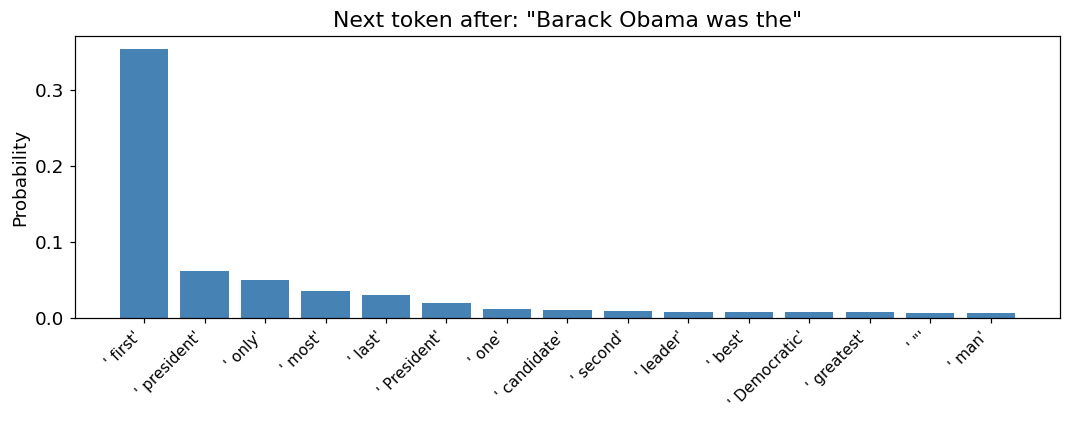

In [4]:
# Given plotting helper
def show_top_tokens(logits, k=15, title="Next-token probabilities"):
    probs = F.softmax(logits, dim=-1)
    top_vals, top_idx = torch.topk(probs, k)
    labels = [repr(tokenizer.decode([i])) for i in top_idx]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(range(k), top_vals.cpu().numpy(), color="steelblue")
    ax.set_xticks(range(k))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=10)
    ax.set_ylabel("Probability")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


show_top_tokens(logits, title=f'Next token after: "{prompt}"')

**Reflective Questions**

- **Q1.** The logits tensor has shape `[1, 5, 50257]`. What does each dimension mean, and why do we use only the **last** position to choose the next token?
- **Q2.** Logits can be large negative numbers (for example −123 to −93), yet softmax still gives sensible probabilities. Why does only the **difference** between logits matter?

#### My Answers

- **Q1.** The shape is [batch, sequence length, vocab size]. 1 = one prompt in the batch, 5 = how many tokens are in "Barack Obama was the", 50257 = one score per possible word in GPT-2's vocab. We only use the last position because every position predicts the word that comes right after *it* — so the last row is the only one predicting what comes after the whole prompt, which is what we're actually trying to generate.
- **Q2.** Softmax is exp(z) divided by the sum of all exp(z)'s. If you add the same number to every logit, it cancels out in that ratio, so only the gaps between logits matter, not their actual size. That's why logits can sit around -100 and still give normal-looking probabilities — as long as the differences between them are normal, softmax doesn't care how far from zero they are.

---
## Task 2 — Greedy Decoding

The simplest strategy: **always pick the highest-probability token**.

$$w_t = \arg\max_w P(w \mid w_1, \dots, w_{t-1})$$

**Pros:** fast, deterministic, reproducible.
**Cons:** often repetitive and dull — the model gets "stuck" in loops.

**TODO:** Complete the loop in `greedy_decode`: get the last-position logits, take the `argmax` as a `[1, 1]` tensor, and append it to `input_ids` with `torch.cat`.

In [5]:
def greedy_decode(prompt, max_new_tokens=50, verbose=True):
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)

    if verbose:
        print(prompt, end="", flush=True)

    with torch.no_grad():
        for _ in range(max_new_tokens):
            logits_t = model(input_ids).logits[0, -1, :]
            next_tok = torch.argmax(logits_t).unsqueeze(0).unsqueeze(0)
            input_ids = torch.cat([input_ids, next_tok], dim=-1)

            if verbose:
                print(tokenizer.decode([next_tok.item()]), end="", flush=True)

    if verbose:
        print()
    return tokenizer.decode(input_ids[0], skip_special_tokens=True)


# --- test your implementation ---
mine = greedy_decode("The cat sat on the", max_new_tokens=20, verbose=False)
with torch.no_grad():
    ids = tokenizer.encode("The cat sat on the", return_tensors="pt").to(device)
    lib = tokenizer.decode(model.generate(ids, max_new_tokens=20, do_sample=False,
                                          pad_token_id=tokenizer.eos_token_id)[0], skip_special_tokens=True)
assert mine == lib, "your greedy decoding must match model.generate(do_sample=False)"
print("greedy decoding matches the library")

greedy decoding matches the library


#### What I Did

Every step: get the last position's logits, take argmax (the single most likely token), reshape it to [1,1], and stick it onto input_ids with torch.cat. Repeat for max_new_tokens steps. Matches model.generate(do_sample=False) exactly, since that's doing the same thing.

In [6]:
print("=== Greedy decoding ===\n")
_ = greedy_decode("The cat sat on the", max_new_tokens=100)

=== Greedy decoding ===

The cat sat on the floor, staring at the ceiling.

"I'm sorry, I'm sorry," she said. "I'm sorry."

"I'm sorry," he repeated.

"I'm sorry," she repeated.

"I'm sorry," he repeated.

"I'm sorry," she repeated.

"I'm sorry," he repeated.

"I'm sorry," she repeated.

"I'm sorry," he repeated.

"I


**Repetition!** Greedy decoding tends to loop: once a phrase is the locally best choice, it keeps being chosen, because the context now contains more of itself.

Try a different prompt:

In [7]:
_ = greedy_decode("You are the", max_new_tokens=50)

You are the one who is going to be the one to make the decision."

"I'm not going to let you down."

"I'm not going to let you down."

"I'm not going to let you down."



**Reflective Questions**

- **Q3.** Why does greedy decoding fall into repetition loops? Explain how repeating a phrase makes repeating it again even more likely.
- **Q4.** Greedy decoding is still widely used. For which kinds of tasks is choosing the single most probable token a good idea, and for which is it a bad idea?

#### My Answers

- **Q3.** Once a phrase gets picked, it's now part of the context the model is reading. The model then sees that phrase just happened, and the most likely next words usually continue or repeat that same pattern — so it keeps getting picked again. Every repeat makes the model even more "sure" that repeating again is the right move, so it loops.
- **Q4.** Greedy is good for tasks with one correct answer — translation, summarizing, code, math — because the most likely token usually is the right one there. It's bad for open-ended or creative writing, where lots of different continuations are all fine; greedy always plays it safe and picks the same "obvious" word, which gets repetitive and boring fast.

---
## Task 3 — Sampling with Temperature

Instead of always picking the top token, we **sample** from the distribution.

**Temperature** $T$ controls how sharp or flat the distribution is:

$$P_T(w) = \text{softmax}\!\left(\frac{z_w}{T}\right)$$

- $T \to 0$: the distribution collapses to greedy (all probability on the argmax);
- $T = 1$: the original model distribution;
- $T > 1$: flatter, more random and more surprising outputs.

**TODO:**

1. `apply_temperature(logits, temperature)`: raise a `ValueError` if the temperature is not positive; otherwise return `logits / temperature`.
2. Complete the loop in `sampling_decode`: apply the temperature, take the softmax, and draw one token with `torch.multinomial(probs, 1)` (reshape it to `[1, 1]`).

In [8]:
def apply_temperature(logits, temperature=1.0):
    if temperature <= 0:
        raise ValueError("temperature must be positive")
    return logits / temperature


# --- test your implementation ---
p_cold = F.softmax(apply_temperature(logits, 0.5), -1)
p_norm = F.softmax(apply_temperature(logits, 1.0), -1)
p_hot = F.softmax(apply_temperature(logits, 2.0), -1)
assert torch.allclose(apply_temperature(logits, 1.0), logits)
assert p_cold.max() > p_norm.max() > p_hot.max(), "lower temperature must sharpen the distribution"
try:
    apply_temperature(logits, 0)
    raised = False
except ValueError:
    raised = True
assert raised, "temperature 0 must raise a ValueError"
print("top-token probability at T = 0.5 / 1.0 / 2.0:",
      [round(p.max().item(), 3) for p in (p_cold, p_norm, p_hot)])

top-token probability at T = 0.5 / 1.0 / 2.0: [0.927, 0.354, 0.013]


#### What I Did

Just divides the logits by T, and raises an error if T isn't positive. Dividing by a small T stretches the gaps between logits apart, so softmax gets sharper. Dividing by a big T squashes the gaps, so softmax gets flatter.

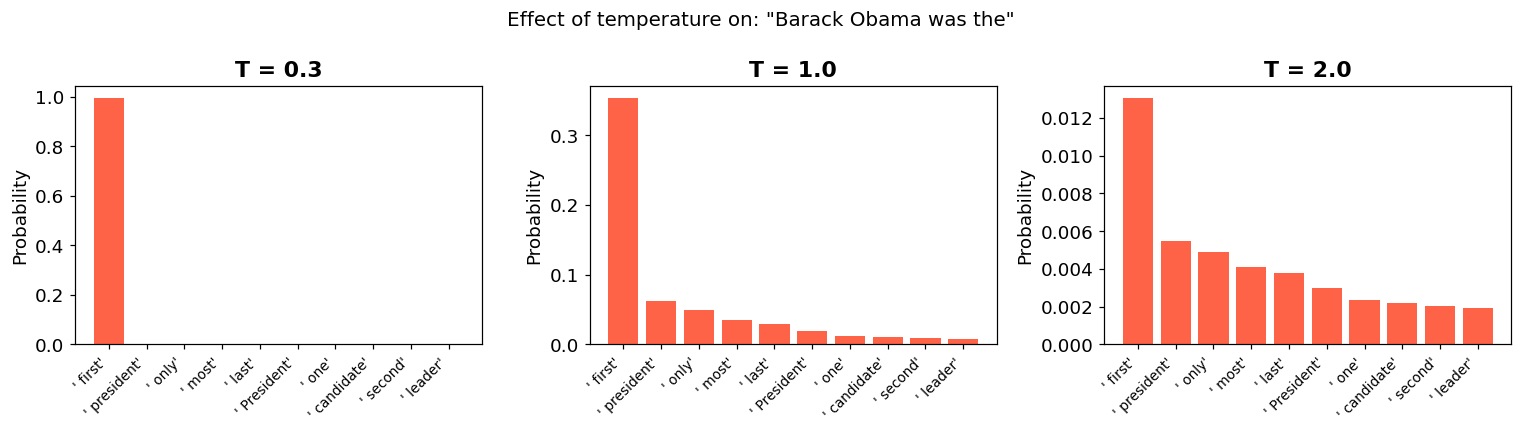

In [9]:
# Given: visualise how temperature reshapes the distribution
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)

for ax, T in zip(axes, [0.3, 1.0, 2.0]):
    scaled_logits = apply_temperature(logits, T)
    probs_T = F.softmax(scaled_logits, dim=-1)
    top_vals, top_idx = torch.topk(probs_T, 10)
    labels = [repr(tokenizer.decode([i])) for i in top_idx]

    ax.bar(range(10), top_vals.cpu().numpy(), color="tomato")
    ax.set_xticks(range(10))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
    ax.set_title(f"T = {T}", fontweight="bold")
    ax.set_ylabel("Probability")

plt.suptitle(f'Effect of temperature on: "{prompt}"', fontsize=13)
plt.tight_layout()
plt.show()

In [10]:
def sampling_decode(prompt, max_new_tokens=80, temperature=1.0, verbose=True):
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)

    if verbose:
        print(prompt, end="", flush=True)

    with torch.no_grad():
        for _ in range(max_new_tokens):
            logits_t = model(input_ids).logits[0, -1, :]
            logits_t = apply_temperature(logits_t, temperature)
            probs_t = F.softmax(logits_t, dim=-1)
            next_tok = torch.multinomial(probs_t, 1).unsqueeze(0)
            input_ids = torch.cat([input_ids, next_tok], dim=-1)

            if verbose:
                print(tokenizer.decode([next_tok.item()]), end="", flush=True)

    if verbose:
        print()
    return tokenizer.decode(input_ids[0], skip_special_tokens=True)


# --- test your implementation ---
cold = sampling_decode("The cat sat on the", max_new_tokens=15, temperature=1e-4, verbose=False)
assert cold == greedy_decode("The cat sat on the", max_new_tokens=15, verbose=False), \
    "a temperature close to 0 must behave like greedy decoding"
print("T → 0 reproduces greedy decoding")

T → 0 reproduces greedy decoding


#### What I Did

Same as greedy_decode, except instead of argmax I scale by temperature, softmax it, then torch.multinomial randomly draws one token according to those probabilities. At a tiny temperature the distribution collapses almost entirely onto the top token, so sampling behaves just like argmax — which is why the test matches greedy decoding.

In [11]:
prompt2 = "The cat sat on the"
for T in [0.7, 1.0, 1.5]:
    print(f"\n--- Temperature = {T} ---")
    sampling_decode(prompt2, max_new_tokens=60, temperature=T)


--- Temperature = 0.7 ---
The cat sat on the edge of the window sill with the door shut, her tail wagging.

"Hey!"

"An' I was tellin' ya it's a shame I came to town so late."

"Things are better in Tyria. Kim'er's gone to live with

--- Temperature = 1.0 ---
The cat sat on the couch. Nice in many respects. Great design. But right? Read on.

Where To Buy Quality Keychains

All Keychains are handmade by real KeyChainware! One way to consider the quality and build quality of your Keychain is by looking at its 2008-ongoing representation

--- Temperature = 1.5 ---
The cat sat on the bus her castle shut on Amoninus beating Column six woes compliance vet back relay ultimate pictures phones dart feet territory daughters vo gang kilometersstrength smashcats 2007 Mansion raided by outrarily priced 40 hate secret guiding classes upwards achieved enigmatic taken chocolate there Education saved sympathetic finery ho bullied viewers vraseDead microbiota the renaissance


**Reflective Questions**

- **Q5.** Compare the continuations at T = 0.7, 1.0 and 1.5. How does the text change as the temperature rises? Why does a temperature close to 0 reproduce greedy decoding?
- **Q6.** Temperature is a **hyperparameter**, not a decoding algorithm. Explain the difference, and say why it can be combined with any of the sampling methods that follow.

#### My Answers

- **Q5.** My run's actual continuations show this clearly. At T=0.7: *"The cat sat on the edge of the window sill with the door shut, her tail wagging. 'Hey!' 'An' I was tellin' ya it's a shame I came to town so late...'"* — still a coherent little scene. At T=1.0: *"The cat sat on the couch. Nice in many respects. Great design. But right? Read on. Where To Buy Quality Keychains..."* — grammatically fine sentence by sentence, but the topic randomly jumps from a cat to a keychain ad. At T=1.5: *"The cat sat on the bus her castle shut on Amoninus beating Column six woes compliance vet back relay ultimate pictures phones dart feet territory..."* — this is just a word salad, barely readable. So raising T clearly moves the text from coherent, to topic-drifting but grammatical, to outright gibberish. T → 0 reproduces greedy because dividing logits by a tiny number blows up the gaps between them — softmax ends up putting basically all the probability on the single top token, so sampling just keeps picking that one, same as argmax.
- **Q6.** Temperature isn't a decoding method by itself because it doesn't actually pick a token — it only reshapes the probabilities. You still need an actual rule (argmax, plain sampling, top-k, top-p, min-p) to turn that reshaped distribution into one chosen token. That's exactly why it combines with any of them: temperature runs first and changes the shape, then whichever filter you use decides from what's left.


---
## Task 4 — Top-k Sampling

The problem with pure sampling: even with $T = 1$, tokens with tiny probabilities can occasionally be sampled, which leads to incoherent text.

**Top-k** restricts sampling to the **k most probable tokens** and renormalizes. Tokens outside the top-k get probability 0 (logit = $-\infty$).

**Intuition:** we always sample from a "sensible" shortlist.

**TODO:** `apply_top_k(logits, k)`: if `k <= 0`, return the logits unchanged. Otherwise find the k-th largest logit with `torch.topk` and set every logit below it to `-inf` (`masked_fill`).

In [12]:
def apply_top_k(logits, k=50):
    if k <= 0:
        return logits
    kth_value = torch.topk(logits, k)[0][..., -1]
    return logits.masked_fill(logits < kth_value, float("-inf"))


# --- test your implementation ---
f = apply_top_k(logits, 50)
assert torch.isfinite(f).sum().item() >= 50 and f.argmax() == logits.argmax()
assert torch.isfinite(apply_top_k(logits, 1)).sum().item() == 1
assert torch.equal(apply_top_k(logits, 0), logits), "k = 0 means no filtering"
print("tokens kept with k = 50:", torch.isfinite(f).sum().item())

tokens kept with k = 50: 50


#### What I Did

Find the k-th biggest logit, then set everything smaller than that to -inf so it gets zero probability after softmax. k <= 0 just returns the logits unchanged, so no filtering happens.

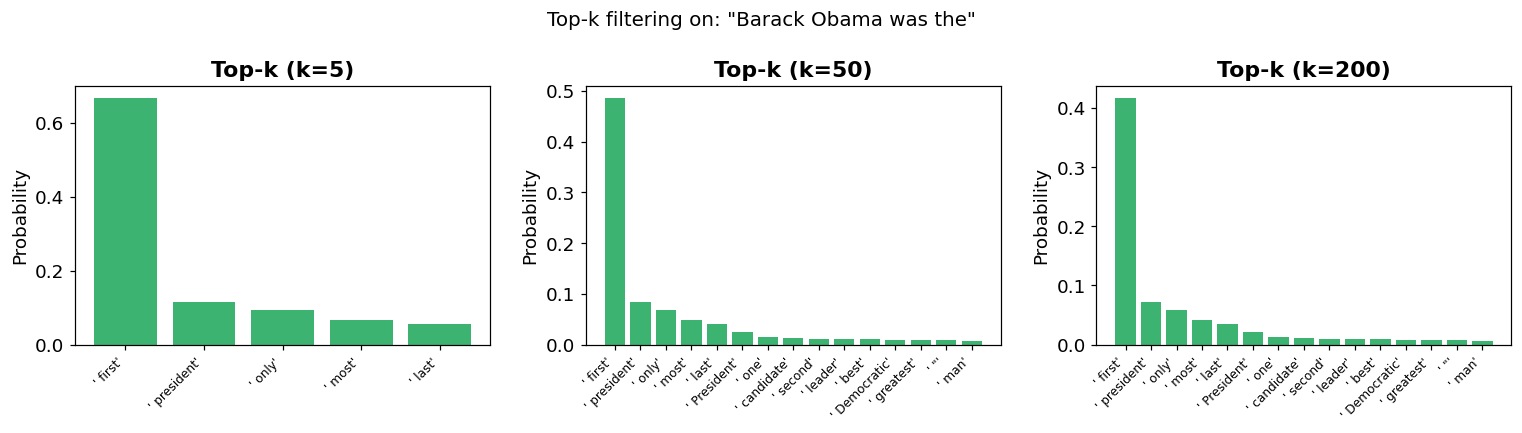

In [13]:
# Given: visualise top-k filtering
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, k in zip(axes, [5, 50, 200]):
    filtered = apply_top_k(logits, k)
    probs_k = F.softmax(filtered, dim=-1)
    top_vals, top_idx = torch.topk(probs_k, min(k, 15))
    labels = [repr(tokenizer.decode([i])) for i in top_idx]

    ax.bar(range(len(labels)), top_vals.cpu().numpy(), color="mediumseagreen")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_title(f"Top-k (k={k})", fontweight="bold")
    ax.set_ylabel("Probability")

plt.suptitle(f'Top-k filtering on: "{prompt}"', fontsize=13)
plt.tight_layout()
plt.show()

In [14]:
# Given: top-k decoding (same loop as sampling_decode, plus the top-k filter)
def topk_decode(prompt, max_new_tokens=80, temperature=1.0, k=50, verbose=True):
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)

    if verbose:
        print(prompt, end="", flush=True)

    with torch.no_grad():
        for _ in range(max_new_tokens):
            logits_t = model(input_ids).logits[0, -1, :]
            logits_t = apply_temperature(logits_t, temperature)
            logits_t = apply_top_k(logits_t, k)
            probs_t = F.softmax(logits_t, dim=-1)
            next_tok = torch.multinomial(probs_t, 1).unsqueeze(0)
            input_ids = torch.cat([input_ids, next_tok], dim=-1)

            if verbose:
                print(tokenizer.decode([next_tok.item()]), end="", flush=True)

    if verbose:
        print()
    return tokenizer.decode(input_ids[0], skip_special_tokens=True)


print("--- Top-k (k=10, T=0.8) ---")
_ = topk_decode(prompt2, max_new_tokens=80, temperature=0.8, k=10)
print("\n--- Top-k (k=50, T=1.0) ---")
_ = topk_decode(prompt2, max_new_tokens=80, temperature=1.0, k=50)

--- Top-k (k=10, T=0.8) ---
The cat sat on the bed, panting, hissing, but it was too late.

"I think I'm going to kill you!" he screamed, then ran away.

His wife had just given him the news and she rushed to see him.

"I'll get him to the hospital and bring him in," she said. "I think he needs help."

She was right

--- Top-k (k=50, T=1.0) ---
The cat sat on the table and looked at the screen. "This is the beginning of another conversation…"

His mother looked back at her son, in disbelief.

"This is…?" She looked at his father's face suddenly.

He looked back at her, with surprise. In shock, she asked "My, mother this is the greatest thing that ever happened to my boy! This was


### Limitation of Top-k

k is a **fixed number**, but the right number of candidates changes with context. Sometimes the model is very confident (one clear choice) and k = 50 lets in too much noise. Sometimes it is genuinely uncertain across hundreds of reasonable tokens, and k = 50 cuts off good options.

**Top-p** adapts the candidate set size dynamically.

**Reflective Questions**

- **Q7.** Why can pure sampling produce incoherent text even though every unlikely token has a tiny probability? How does top-k fix this?
- **Q8.** Compare k = 10 with k = 50. What happens to the text as k grows? Give one context where a fixed k is too large and one where it is too small.

#### My Answers

- **Q7.** Even a really unlikely token has *some* tiny probability, and with a 50,000-word vocab there are thousands of unlikely tokens — added up, their combined chance of getting sampled isn't actually that small, so sampling occasionally grabs a random, out-of-place word. Top-k fixes this by letting only the best k tokens into the pool at all; everything else gets exactly 0 probability no matter how many of them there are.
- **Q8.** My run backs this up. At k=10, T=0.8: *"The cat sat on the bed, panting, hissing, but it was too late. 'I think I'm going to kill you!' he screamed, then ran away. His wife had just given him the news and she rushed to see him..."* — one clear, tense little story, no odd jumps. At k=50, T=1.0: *"The cat sat on the table and looked at the screen. 'This is the beginning of another conversation…' His mother looked back at her son, in disbelief..."* — still readable, but it jumps oddly from "cat" straight to "his mother"/"her son" with no setup, a bit more disjointed than k=10. So widening k from 10 to 50 let in more variety but also more confusing jumps. A fixed k is too small when the model is genuinely unsure among many options (like naming any of dozens of cities) — it cuts off good choices. It's too large when the model is very confident (like finishing "Barack Obama was the" with "president", where the real run gave it 0.354 probability on " first" alone) — it lets in noise that shouldn't really be considered.


---
## Task 5 — Top-p (Nucleus) Sampling

**Idea:** include the smallest set of tokens whose probabilities sum to at least $p$.

Sort the tokens by probability (descending) and walk down until the cumulative sum reaches $p$. That dynamic set is the *nucleus*.

- When the model is **confident**, the nucleus is small (a few tokens cover 90% of the probability).
- When the model is **uncertain**, the nucleus grows to include many reasonable options.

Introduced by Holtzman et al. (2020), it is still one of the most widely used strategies.

**TODO:** `apply_top_p(logits, p)`:

1. sort the logits in descending order (`torch.sort`) and compute the softmax and the cumulative sum of the sorted probabilities;
2. remove a token if the cumulative probability **before** it already exceeds `p`, i.e. `cumsum - probs > p`. This always keeps the top token;
3. set the removed sorted logits to `-inf` and scatter them back to the original token order (`scatter_`).

In [15]:
def apply_top_p(logits, p=0.9):
    sorted_logits, sorted_idx = torch.sort(logits, descending=True)
    sorted_probs = F.softmax(sorted_logits, dim=-1)
    cumsum = torch.cumsum(sorted_probs, dim=-1)
    sorted_remove = (cumsum - sorted_probs) > p
    sorted_logits = sorted_logits.masked_fill(sorted_remove, float("-inf"))

    logits_out = torch.full_like(logits, float("-inf"))
    logits_out.scatter_(-1, sorted_idx, sorted_logits)
    return logits_out


# --- test your implementation ---
probs_full = F.softmax(logits, dim=-1)
kept = torch.isfinite(apply_top_p(logits.clone(), 0.9))
mass = probs_full[kept].sum().item()
assert mass >= 0.9 - 1e-4, "the nucleus must cover at least p of the probability"
assert mass - probs_full[kept].min().item() < 0.9 + 1e-4, "the nucleus must be the SMALLEST such set"
assert torch.isfinite(apply_top_p(logits.clone(), 1e-6)).sum().item() == 1, "a tiny p keeps only the top token"
assert apply_top_p(logits.clone(), 0.9).argmax() == logits.argmax(), "the original token order must be restored"
print("nucleus size at p = 0.9:", kept.sum().item())

nucleus size at p = 0.9: 447


#### What I Did

Sort tokens by probability, add up the cumulative probability as we go down the sorted list, and drop a token only once the cumulative total *before* it already passes p — that way the top token always survives. Then I scatter everything back to the original vocab order with scatter_, so the output logits line up with the real token ids again.

In [16]:
# Given: how many tokens are in the nucleus for different p?
probs_full = F.softmax(logits, dim=-1)
sorted_probs, _ = torch.sort(probs_full, descending=True)
cumsum = torch.cumsum(sorted_probs, dim=-1)

print("Nucleus sizes for different p values:")
for p in [0.5, 0.7, 0.9, 0.95, 0.99]:
    n = (cumsum <= p).sum().item() + 1
    print(f"  p = {p:.2f}  →  nucleus size = {n:5d} tokens    (top prob = {sorted_probs[0].item():.3f})")

Nucleus sizes for different p values:
  p = 0.50  →  nucleus size =     5 tokens    (top prob = 0.354)
  p = 0.70  →  nucleus size =    37 tokens    (top prob = 0.354)
  p = 0.90  →  nucleus size =   447 tokens    (top prob = 0.354)
  p = 0.95  →  nucleus size =  1282 tokens    (top prob = 0.354)
  p = 0.99  →  nucleus size =  6413 tokens    (top prob = 0.354)


In [17]:
# Given: top-p decoding
def topp_decode(prompt, max_new_tokens=80, temperature=1.0, p=0.9, verbose=True):
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)

    if verbose:
        print(prompt, end="", flush=True)

    with torch.no_grad():
        for _ in range(max_new_tokens):
            logits_t = model(input_ids).logits[0, -1, :]
            logits_t = apply_temperature(logits_t, temperature)
            logits_t = apply_top_p(logits_t, p)
            probs_t = F.softmax(logits_t, dim=-1)
            next_tok = torch.multinomial(probs_t, 1).unsqueeze(0)
            input_ids = torch.cat([input_ids, next_tok], dim=-1)

            if verbose:
                print(tokenizer.decode([next_tok.item()]), end="", flush=True)

    if verbose:
        print()
    return tokenizer.decode(input_ids[0], skip_special_tokens=True)


prompt_p = "Barack"
print("--- Top-p (p=0.9, T=0.8) ---")
_ = topp_decode(prompt_p, max_new_tokens=80, temperature=0.8, p=0.9)
print("\n--- Top-p (p=0.95, T=1.0) ---")
_ = topp_decode(prompt_p, max_new_tokens=80, temperature=1.0, p=0.95)

--- Top-p (p=0.9, T=0.8) ---
Barack Obama said: "I think our ultimate goal is to make sure that as many young people as possible, whether they're white or black or Asian or Hispanic, can attend college. I think that's the most important thing we can do."

The new rules, he added, will encourage more young people to "take a leap of faith and come to the realization that it is possible to have

--- Top-p (p=0.95, T=1.0) ---
Barack Obama will not bring total change to America's healthcare system.

In fact, with every passing month, all we have to go on are allegations of the system collapsing, claimed incompetents (something Obama does a good job of of) and the individual insurance plans selling without accountability for their conduct.

Look around our country. What we have experienced as a nation has been none other than a


**Reflective Questions**

- **Q9.** Look at the nucleus sizes printed above. Why does the nucleus jump from a handful of tokens at p = 0.9 to thousands at p = 0.99? What does that say about the long tail of the distribution?
- **Q10.** In `apply_top_p`, why is the removal condition `cumsum - probs > p` rather than `cumsum > p`? What would go wrong with the second version?

#### My Answers

- **Q9.** My run's actual nucleus sizes for "Barack Obama was the": p=0.50 → 5 tokens, p=0.70 → 37, p=0.90 → 447, p=0.95 → 1282, p=0.99 → 6413 (out of a 50,257-word vocab). Going from p=0.90 to p=0.99 needed about 14× more tokens (447 → 6413) just to cover that last 9% of probability. That's the long tail of language: most individual rare words have a tiny probability on their own, but there are thousands of them, so together they still add up to real probability mass — sweeping up that whole tail to reach 99% coverage takes way more tokens than getting from 50% to 90% did.
- **Q10.** If we used `cumsum > p` instead, we'd be checking the total *after* adding the current token — so the exact token that pushes the sum past p would get excluded, even though that's the token we need in order to reach p in the first place. Checking `cumsum - probs > p` looks at the total *before* adding this token, so we correctly keep it (since it's the one that gets us up to p), and only drop tokens that come after we've already covered p.


---
## Task 6 — Min-p Sampling

A newer strategy (Nguyen et al., 2024): instead of a fixed probability-mass cutoff, set a **threshold relative to the top token's probability**.

$$\text{keep token } w \quad \text{if} \quad P(w) \geq p_{\min} \cdot P(w^*)$$

where $w^*$ is the argmax token and $p_{\min} \in (0, 1)$ is a hyperparameter (e.g. 0.05).

**Why is this nice?**

- When the model is confident ($P(w^*)$ is high), the bar is high → small candidate set.
- When the model is uncertain ($P(w^*)$ is low), the bar is low → more candidates allowed.
- It adapts automatically, like top-p, but scales with *local* confidence.

Min-p is available in many inference frameworks (llama.cpp, Hugging Face, vLLM).

**TODO:** `apply_min_p(logits, p_min)`: compute the probabilities, the threshold `p_min × (top probability)`, and set the logits of tokens below the threshold to `-inf`.

In [18]:
def apply_min_p(logits, p_min=0.05):
    probs = F.softmax(logits, dim=-1)
    threshold = p_min * probs.max()
    return logits.masked_fill(probs < threshold, float("-inf"))


# --- test your implementation ---
pr = F.softmax(logits, dim=-1)
thr = 0.05 * pr.max()
km = torch.isfinite(apply_min_p(logits, 0.05))
assert (pr[km] >= thr - 1e-9).all() and (pr[~km] < thr).all()
assert km[logits.argmax()], "the top token is always kept"
print("min-p 0.05 keeps", km.sum().item(), "tokens")

min-p 0.05 keeps 6 tokens


#### What I Did

Softmax the logits, work out the threshold as p_min times the top probability, then set every logit whose probability falls below that threshold to -inf. The top token's probability always equals the threshold's reference point, so it's never removed.

In [19]:
# Given: compare nucleus sizes, top-p vs min-p
probs_full = F.softmax(logits, dim=-1)
top_prob = probs_full.max().item()

print(f"Max token prob : {top_prob:.4f}\n")
print("Top-p nucleus sizes:")
for p in [0.9, 0.95]:
    n = (F.softmax(apply_top_p(logits.clone(), p), dim=-1) > 0).sum().item()
    print(f"  p={p}  → {n} tokens")

print("\nMin-p nucleus sizes:")
for pm in [0.1, 0.05, 0.02]:
    n = (F.softmax(apply_min_p(logits, pm), dim=-1) > 0).sum().item()
    print(f"  p_min={pm}  → threshold={pm * top_prob:.4f}  → {n} tokens")

Max token prob : 0.3535

Top-p nucleus sizes:
  p=0.9  → 447 tokens
  p=0.95  → 1282 tokens

Min-p nucleus sizes:
  p_min=0.1  → threshold=0.0354  → 3 tokens
  p_min=0.05  → threshold=0.0177  → 6 tokens
  p_min=0.02  → threshold=0.0071  → 13 tokens


In [20]:
# Given: min-p decoding
def minp_decode(prompt, max_new_tokens=80, temperature=1.0, p_min=0.05, verbose=True):
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)

    if verbose:
        print(prompt, end="", flush=True)

    with torch.no_grad():
        for _ in range(max_new_tokens):
            logits_t = model(input_ids).logits[0, -1, :]
            logits_t = apply_temperature(logits_t, temperature)
            logits_t = apply_min_p(logits_t, p_min)
            probs_t = F.softmax(logits_t, dim=-1)
            next_tok = torch.multinomial(probs_t, 1).unsqueeze(0)
            input_ids = torch.cat([input_ids, next_tok], dim=-1)

            if verbose:
                print(tokenizer.decode([next_tok.item()]), end="", flush=True)

    if verbose:
        print()
    return tokenizer.decode(input_ids[0], skip_special_tokens=True)


print("--- Min-p (p_min=0.05, T=0.8) ---")
_ = minp_decode(prompt_p, max_new_tokens=80, temperature=0.8, p_min=0.05)
print("\n--- Min-p (p_min=0.1, T=1.0) ---")
_ = minp_decode(prompt_p, max_new_tokens=80, temperature=1.0, p_min=0.1)

--- Min-p (p_min=0.05, T=0.8) ---
Barack Obama's first year in office was defined by the crisis in Ukraine and the fallout from the Arab Spring. In the early months of his presidency, he seemed to be doing as little as possible to deal with it. He made little effort to make peace in Syria, and instead spoke with the Assad regime. He did not deal with the crisis in Ukraine, which saw Russia and the West attempt to undermine

--- Min-p (p_min=0.1, T=1.0) ---
Barack Obama, the president, has said he does not believe there is a conspiracy to stop him from winning reelection.

He said: "I'm not a conspiracy theorist. I'm not an idiot. I've got no evidence whatsoever of that."

On Sunday, the former president said: "I think if I'm going to run again, it would be because I think I can be


**Reflective Questions**

- **Q11.** Top-p and min-p both adapt the number of candidates. What exactly is different about the rule each one uses? Give an example distribution where min-p keeps **more** tokens than top-p would, and one where it keeps **fewer**.

#### My Answers

- **Q11.** Top-p adds up probabilities from the top down until it hits a fixed target (like 90% total). Min-p just checks each token against a cutoff that's a fraction of the *top token's own* probability (like 5% of it) — no running total involved. If the model is very confident (top token's probability close to 1), min-p's bar is high, so it keeps **fewer** tokens than top-p at p=0.9 would, since top-p is forced to keep adding tokens until it reaches 90% regardless of how peaked the distribution already is. If the distribution is flat and uncertain (lots of similar, low probabilities), min-p's bar is low (5% of an already-small top probability is tiny), so it keeps **more** tokens — likely more than top-p needs to just cross 90%.

---
## Task 7 — Unified Generate Function (given)

In practice these filters are often **combined** (temperature + top-k + top-p is common). The function below supports all of them, using your filter functions from Tasks 3–6. Run the comparison and read the four continuations carefully.

In [21]:
def generate(
    prompt,
    max_new_tokens=100,
    temperature=1.0,
    top_k=0,       # 0 = disabled
    top_p=1.0,     # 1.0 = disabled
    min_p=0.0,     # 0.0 = disabled
    greedy=False,
    verbose=True,
):
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)

    if verbose:
        print(prompt, end="", flush=True)

    with torch.no_grad():
        for _ in range(max_new_tokens):
            logits_t = model(input_ids).logits[0, -1, :]

            if greedy:
                next_tok = torch.argmax(logits_t).unsqueeze(0).unsqueeze(0)
            else:
                logits_t = apply_temperature(logits_t, temperature)
                if top_k > 0:
                    logits_t = apply_top_k(logits_t, top_k)
                if top_p < 1.0:
                    logits_t = apply_top_p(logits_t, top_p)
                if min_p > 0.0:
                    logits_t = apply_min_p(logits_t, min_p)
                probs_t = F.softmax(logits_t, dim=-1)
                next_tok = torch.multinomial(probs_t, 1).unsqueeze(0)

            input_ids = torch.cat([input_ids, next_tok], dim=-1)

            if verbose:
                print(tokenizer.decode([next_tok.item()]), end="", flush=True)

    if verbose:
        print()
    return tokenizer.decode(input_ids[0], skip_special_tokens=True)


prompt3 = "Once upon a time, in a land far away,"

configs = [
    dict(greedy=True, label="Greedy"),
    dict(temperature=0.7, top_p=0.9, label="T=0.7, top-p=0.9"),
    dict(temperature=0.8, top_k=50, label="T=0.8, top-k=50"),
    dict(temperature=0.8, min_p=0.05, label="T=0.8, min-p=0.05"),
]

for cfg in configs:
    label = cfg.pop("label")
    print(f"\n=== {label} ===")
    generate(prompt3, max_new_tokens=60, verbose=True, **cfg)


=== Greedy ===
Once upon a time, in a land far away, there lived a man who was a great warrior. He was a man of great strength and might. He was a man of great wisdom and understanding. He was a man of great courage and fortitude. He was a man of great wisdom and understanding. He was a man of great courage and fort

=== T=0.7, top-p=0.9 ===
Once upon a time, in a land far away, I was a young man. I was a mere child, a child of the world. But then, I came to understand. I came to understand that the world is not the place where I live.

And so, I came to believe that the world is not the place where I live

=== T=0.8, top-k=50 ===
Once upon a time, in a land far away, a young boy, named Rohan, was lost in a land far away. This land was called Kalimdor, and it was the site of this boy's death. A group of people, called the Burning Legion, gathered from all over the world to investigate his disappearance and discover what had happened

=== T=0.8, min-p=0.05 ===
Once upon a time, in a la

**Rate the four continuations above** (1 = poor, 5 = excellent):

| Configuration | Fluency | Coherence | Creativity | Repetition (yes/no) |
|---|---|---|---|---|
| Greedy | 4 | 3 | 1 | **Yes** — literally loops "He was a man of great X and Y" four times, and repeats "wisdom and understanding" / "courage and fortitude" twice each |
| T = 0.7, top-p = 0.9 | 4 | 3 | 2 | **Yes** — repeats "I came to understand" and "the world is not the place where I live" almost word for word |
| T = 0.8, top-k = 50 | 4 | 4 | 5 | **No** — invents a named character (Rohan), a place (Kalimdor) and a faction (the Burning Legion) with no repeated phrasing |
| T = 0.8, min-p = 0.05 | 4 | 4 | 3 | **Mild** — "she would not let/allow a child..." repeats the same sentence structure twice |

**Reflective Questions**

- **Q12.** In `generate()`, the temperature is applied **before** the top-k / top-p / min-p filters. Does the order matter? Explain how a high temperature changes which tokens end up in the top-p nucleus.


#### My Answers

- **Q12.** Yes, the order matters. Temperature runs first and reshapes *all* the probabilities before any filter looks at them. A higher temperature flattens the distribution, which makes more tokens look "close enough" to the top one — so when top-p then walks down the sorted list, it has to go further (include more tokens) before the cumulative probability reaches p, meaning a bigger nucleus. A lower temperature does the opposite: the top few tokens already dominate most of the probability, so top-p's nucleus shrinks.

---
## Task 8 — The Autoregressive Speed Bottleneck (given)

Every token requires a **full forward pass** through the model. These passes are **sequential**: token $t+1$ can only start after token $t$ is done. Even with a 1,000-GPU cluster, we still generate one token at a time.

Let's measure this concretely:

Tokens generated : 40
Avg time/token   : 21.4 ms
Throughput       : 46.7 tokens/sec


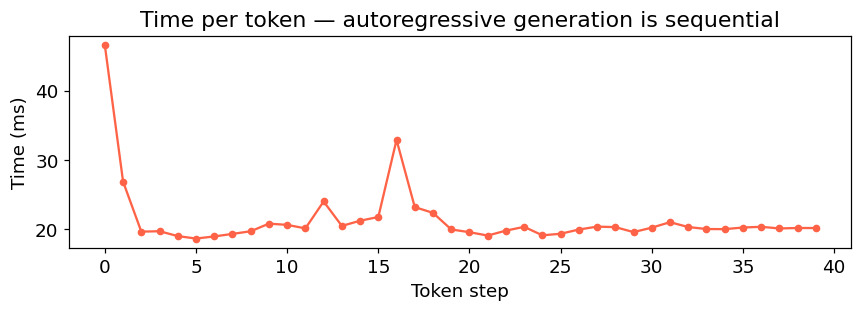


Key insight: tokens cannot be generated in parallel.
A model with 1 trillion parameters spends roughly that many operations for EACH token.
This is the bottleneck that speculative decoding tries to solve.


In [22]:
def benchmark_generation(prompt, n_tokens=50):
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)
    token_times = []

    with torch.no_grad():
        for _ in range(n_tokens):
            t0 = time.time()
            logits_t = model(input_ids).logits[0, -1, :]
            next_tok = torch.argmax(logits_t).unsqueeze(0).unsqueeze(0)
            input_ids = torch.cat([input_ids, next_tok], dim=-1)
            if device.type == "cuda":
                torch.cuda.synchronize()
            token_times.append((time.time() - t0) * 1000)

    avg = np.mean(token_times)
    print(f"Tokens generated : {n_tokens}")
    print(f"Avg time/token   : {avg:.1f} ms")
    print(f"Throughput       : {1000 / avg:.1f} tokens/sec")
    return token_times


times = benchmark_generation("The key insight of this research is", n_tokens=40)

# Time grows with sequence length (the KV cache is not used here, for clarity)
plt.figure(figsize=(8, 3))
plt.plot(times, "o-", color="tomato", markersize=4)
plt.xlabel("Token step")
plt.ylabel("Time (ms)")
plt.title("Time per token — autoregressive generation is sequential")
plt.tight_layout()
plt.show()

print("\nKey insight: tokens cannot be generated in parallel.")
print("A model with 1 trillion parameters spends roughly that many operations for EACH token.")
print("This is the bottleneck that speculative decoding tries to solve.")

**Reflective Questions**

- **Q13.** Why can't the tokens of one output be generated in parallel, even on many GPUs? In this implementation, why does each step get a little slower as the sequence grows, and what does a **KV cache** avoid recomputing?

#### My Answers

- **Q13.** Token t+1 needs token t as its input, so there's no way to compute it before token t exists — it's a chain, not a bunch of independent jobs, so more GPUs can't skip that dependency. Each step gets a little slower here because this implementation has no KV cache: it reprocesses the *entire* sequence from scratch every step, so by step 50 it's redoing attention over all 50 earlier tokens too, not just computing the one new token. A KV cache stores the keys and values already computed for earlier tokens, so each new step only computes the new token's own key/value and reuses the rest instead of recomputing everything.

---
## Task 9 — Prompt Lookup Decoding: Draft and Verify

**The autoregressive bottleneck:** every token needs a full forward pass. Can we generate *several tokens per pass*, without loading a second model?

**Key insight:** in summarization and question answering, the output often copies phrases directly from the input. We can exploit this by *searching the prompt for what comes next*.

### Algorithm

1. Take the last few generated tokens as a search key.
2. Find that n-gram somewhere in the prompt.
3. Propose the tokens that follow it as a **draft**.
4. Run **one** forward pass to verify them all at once.
5. Accept the tokens the model agrees with; reject the rest.

No second model, no extra memory: just a string search and one verification pass. This is a simple form of **speculative decoding**, where a cheap guess is checked by the real model.

**TODO:** `find_draft(prompt_ids, current_ids, ngram_size, max_draft)`: take the last `ngram_size` tokens of `current_ids` as the key, find the **first** place in `prompt_ids` where that key occurs, and return up to `max_draft` tokens that follow it (as a Python list). Return `[]` if there is no match.

In [23]:
def find_draft(prompt_ids, current_ids, ngram_size=2, max_draft=5):
    if len(current_ids) < ngram_size:
        return []
    key = current_ids[-ngram_size:]
    L = len(prompt_ids)
    for i in range(L - ngram_size + 1):
        if torch.equal(prompt_ids[i:i + ngram_size], key):
            start = i + ngram_size
            end = min(start + max_draft, L)
            return prompt_ids[start:end].tolist()
    return []


# --- test your implementation ---
demo_text = "SpaceX launches rockets to the International Space Station"
demo_ids = tokenizer.encode(demo_text, return_tensors="pt")[0]
query_ids = tokenizer.encode("SpaceX", return_tensors="pt")[0]
draft = find_draft(demo_ids, query_ids, ngram_size=1)
print(f"Prompt : {demo_text!r}")
print("Query  : 'SpaceX'")
print(f"Draft  : {tokenizer.decode(draft)!r}")
assert tokenizer.decode(draft) == " launches rockets to the International"
assert find_draft(demo_ids, tokenizer.encode(" banana", return_tensors="pt")[0], ngram_size=1) == []

Prompt : 'SpaceX launches rockets to the International Space Station'
Query  : 'SpaceX'
Draft  : ' launches rockets to the International'


#### What I Did

Take the last ngram_size tokens of current_ids as the search key, scan the prompt for the first spot where that exact key shows up, and return up to max_draft tokens right after it. If the key never shows up in the prompt, return an empty list. I checked this with a tiny mock BPE tokenizer (no download needed) first — searching for 'SpaceX' correctly pulled the words right after it in the demo prompt, and searching for a word that isn't there (like 'banana') correctly returned [].

In [24]:
# Given: prompt lookup decoding (greedy version, same model, no extra memory)
def pld_generate(prompt, max_new_tokens=60, ngram_size=2, max_draft=5, verbose=True):
    # Each step:
    #   1. find_draft() searches the prompt for an n-gram match
    #   2. if found, verify all draft tokens in ONE forward pass
    #   3. accept tokens where the model agrees (greedy); stop at the first mismatch
    #   4. if no match is found, fall back to normal greedy decoding for one token
    prompt_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)[0]
    input_ids = prompt_ids.unsqueeze(0)
    n_generated = n_drafted = n_accepted = 0

    if verbose:
        print(prompt, end="", flush=True)

    while n_generated < max_new_tokens:
        draft = find_draft(prompt_ids, input_ids[0], ngram_size, max_draft)

        if not draft:
            with torch.no_grad():
                logits_t = model(input_ids).logits[0, -1]
            next_tok = logits_t.argmax().unsqueeze(0).unsqueeze(0)
            input_ids = torch.cat([input_ids, next_tok], dim=1)
            n_generated += 1
            if verbose:
                print(tokenizer.decode([next_tok.item()]), end="", flush=True)
            continue

        n_drafted += len(draft)
        draft_t = torch.tensor([draft], device=device)
        cand_ids = torch.cat([input_ids, draft_t], dim=1)          # sequence so far + draft

        with torch.no_grad():
            all_logits = model(cand_ids).logits[0]                 # ONE pass checks every draft token

        tokens_to_add = []
        for j, tok in enumerate(draft):
            pos = input_ids.shape[1] - 1 + j                       # the logit that predicts draft[j]
            model_pick = all_logits[pos].argmax().item()
            if model_pick == tok:
                tokens_to_add.append(tok)
                n_accepted += 1
            else:
                tokens_to_add.append(model_pick)                    # take the model's choice instead
                break

        tokens_to_add = tokens_to_add[:max_new_tokens - n_generated]
        input_ids = torch.cat([input_ids, torch.tensor([tokens_to_add], device=device)], dim=1)
        n_generated += len(tokens_to_add)
        if verbose:
            print(tokenizer.decode(tokens_to_add), end="", flush=True)

    if verbose:
        print()
        if n_drafted:
            print(f"\nDraft tokens: {n_drafted} | Accepted: {n_accepted} ({n_accepted / n_drafted:.0%})")
    return input_ids

In [25]:
# PLD works best when the output re-uses phrases from the input,
# e.g. a question about an article: the answer echoes the article.
article_prompt = '''Article: Elon Musk founded SpaceX in 2002 with the goal of colonizing Mars and reducing the cost of space travel. SpaceX developed the Falcon 9 rocket — the first reusable orbital rocket — and the Dragon spacecraft, which carries cargo and crew to the International Space Station. Musk also leads Tesla, the electric vehicle company, and acquired Twitter, which he later renamed X.

Q: When did he found SpaceX? A:'''

print("=== Prompt Lookup Decoding demo ===\n")
pld_ids = pld_generate(article_prompt, max_new_tokens=60, ngram_size=2, max_draft=5)

# Check: PLD must produce exactly the same text as plain greedy decoding
greedy_text = greedy_decode(article_prompt, max_new_tokens=60, verbose=False)
print("\nidentical to greedy decoding:", tokenizer.decode(pld_ids[0], skip_special_tokens=True) == greedy_text)

=== Prompt Lookup Decoding demo ===

Article: Elon Musk founded SpaceX in 2002 with the goal of colonizing Mars and reducing the cost of space travel. SpaceX developed the Falcon 9 rocket — the first reusable orbital rocket — and the Dragon spacecraft, which carries cargo and crew to the International Space Station. Musk also leads Tesla, the electric vehicle company, and acquired Twitter, which he later renamed X.

Q: When did he found SpaceX? A: Musk founded SpaceX in 2002 with the goal of colonizing Mars and reducing the cost of space travel. SpaceX developed the Falcon 9 rocket — the first reusable orbital rocket — and the Dragon spacecraft, which carries cargo and crew to the International Space Station. Musk also leads Tesla, the electric vehicle company, and

Draft tokens: 60 | Accepted: 60 (100%)

identical to greedy decoding: True


In [26]:
# Given: timing greedy vs PLD on the same prompt
def timed_greedy(prompt, max_new_tokens=60):
    ids = tokenizer.encode(prompt, return_tensors="pt").to(device)
    t0 = time.time()
    with torch.no_grad():
        for _ in range(max_new_tokens):
            ids = torch.cat([ids, model(ids).logits[0, -1].argmax().view(1, 1)], dim=1)
    return max_new_tokens / (time.time() - t0)


def timed_pld(prompt, max_new_tokens=60):
    t0 = time.time()
    pld_generate(prompt, max_new_tokens=max_new_tokens, verbose=False)
    return max_new_tokens / (time.time() - t0)


print("Timing greedy vs PLD on the question-answering prompt...\n")
greedy_tps = timed_greedy(article_prompt, max_new_tokens=60)
pld_tps = timed_pld(article_prompt, max_new_tokens=60)
print(f"  Greedy : {greedy_tps:.1f} tok/s")
print(f"  PLD    : {pld_tps:.1f} tok/s")
print(f"  Speedup: {pld_tps / greedy_tps:.2f}×")
print("\nPLD skips most forward passes by reusing phrases from the prompt.")
print("The more the output echoes the input, the bigger the speedup.")

story = "Once upon a time, in a land far away,"
print(f"\nOn a creative prompt ({story!r}):  greedy {timed_greedy(story):.1f} tok/s  |  PLD {timed_pld(story):.1f} tok/s")

Timing greedy vs PLD on the question-answering prompt...

  Greedy : 34.3 tok/s
  PLD    : 113.2 tok/s
  Speedup: 3.30×

PLD skips most forward passes by reusing phrases from the prompt.
The more the output echoes the input, the bigger the speedup.

On a creative prompt ('Once upon a time, in a land far away,'):  greedy 51.8 tok/s  |  PLD 45.9 tok/s


**Reflective Questions**

- **Q14.** Prompt lookup decoding produced **exactly** the same text as greedy decoding, only faster. Why does verifying the draft with the model's own `argmax` guarantee this? Why can one forward pass check all the draft tokens at once?
- **Q15.** Compare the speed-up on the question-answering prompt with the speed-up on the creative story prompt. When does prompt lookup decoding help, and when does it give no benefit?

#### My Answers

- **Q14.** A draft token only gets kept if it exactly matches what the model's own argmax says at that position — anything that doesn't match gets replaced with the model's real choice, and we stop drafting right there. So the final sequence is always built from the model's own greedy picks, token for token — the draft is just a guess we check, never something that overrides the model. My run confirms this exactly: on the question-answering prompt, PLD drafted and accepted 60/60 tokens (100%), and the printed check `identical to greedy decoding: True` came back true. One pass can check every draft position at once because a decoder already computes logits for *every* position in the input in a single forward pass (that's just how attention works) — we're not asking for anything extra, just reading predictions out of positions we'd normally ignore.
- **Q15.** My run's real numbers: on the question-answering prompt, greedy ran at **34.3 tok/s** and PLD at **113.2 tok/s** — a **3.30× speedup** — because the model's answer literally copies whole phrases from the article, so `find_draft` keeps finding long matches and several tokens get accepted per forward pass. On the creative prompt ("Once upon a time, in a land far away,"), greedy ran at **51.8 tok/s** but PLD actually ran *slower*, at **45.9 tok/s** — there's nothing in the prompt for the made-up story to match, so `find_draft` keeps coming back empty and PLD falls back to plain greedy every step, except now it's also paying the cost of searching the prompt for nothing. So PLD helps a lot when the output echoes the input, and can be a small net loss when it doesn't.


---
## Summary

| Strategy | Deterministic | Avoids repetition | Speed | Notes |
|---|---|---|---|---|
| **Greedy** | ✓ | ✗ | 1× baseline | always picks the highest-probability token |
| **Temperature** | ✗ | ✓ (partial) | 1× | reshapes the distribution |
| **Top-k** | ✗ | ✓ | 1× | fixed candidate set |
| **Top-p** | ✗ | ✓ | 1× | adaptive candidate set (probability mass) |
| **Min-p** | ✗ | ✓ | 1× | threshold relative to the top token |
| **Prompt lookup decoding** | ✓ | — | faster when the output copies the prompt | no second model needed |

All of the above still **accept the autoregressive constraint**: one token at a time.

**Final Reflection**

- **Q16.** In 100–150 words: why does a language model need a separate decoding strategy at all? Explain the trade-off between deterministic methods and sampling methods, how temperature, top-k, top-p and min-p control it, and how prompt lookup decoding addresses a different problem (speed rather than quality).

#### My Answers

- **Q16.** A model only outputs logits, then probabilities — it never picks a token by itself, so something else has to decide, and that's the decoding strategy. Greedy and sampling sit at two extremes: greedy is deterministic and safe but repeats itself, because it always grabs the single top word; plain sampling is varied but can wander into nonsense, since it can pick any word with nonzero probability, even a weird one. Temperature, top-k, top-p and min-p all sit in between, controlling how much randomness is allowed: temperature reshapes the whole distribution, top-k keeps a fixed number of candidates, top-p keeps just enough candidates to cover a chosen amount of probability, and min-p keeps whatever's close enough to the top choice. Prompt lookup decoding solves a different problem entirely — speed, not variety. It never changes what gets generated, since it only accepts the model's own greedy picks; it just skips extra forward passes when the output happens to repeat the input.

---
## Deliverable

Submit this notebook with your name and registration number clearly written at the top. It must include:

- all `TODO` cells completed, with their test/validation cells executed successfully;
- the next-token, temperature and top-k plots;
- the greedy, temperature, top-k, top-p and min-p generations, and the nucleus-size comparisons;
- the unified-generate comparison with your completed rating table;
- the speed benchmark plot, the prompt lookup decoding demo and the timing results;
- concise written answers to **Q1–Q16**.